#### In this notebook i will use the lsm.py to see what happens to a gaussian input and the symbol that is recovvered

In [40]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

print(sys.executable)

c:\Users\henri\Documents\progging\Prosjekt_Master\.venv\Scripts\python.exe


In [41]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 

from nonlinear.lsm import LSM
from nonlinear.solvers import KdV, Whitham
from linear.help import *


In [42]:
N = 2**8
P = 20
x = np.linspace(-P/2, P/2, N, endpoint=False)
g = np.exp(-x**2)



In [43]:
# plt.plot(x, g);

In [44]:
# kdv1 = KdV(P = P, dt = 5e-3, T = 5, u0 = g, save_every=1)
kdv1 = Whitham(P = P, dt = 5e-3, T = 5, u0 = g, save_every=1)
t,u = kdv1.splitStep()

In [45]:
animate_solution_nb(x, u)

In [46]:
lsm = LSM([u], kdv1.dt)
lsm_X = lsm.lsm()



In [50]:
half = N//2
idx = N//2 -1
idx_p = N//2 + idx
idx_n = N//2 - idx + 1
ell , n = lsm.fit_symbol(k = np.fft.fftfreq(kdv1.N, d = kdv1.P/kdv1.N)*2*np.pi, idx_range = [idx_n, idx_p], deg = 5)

In [48]:
fit_table(ell, n, part="imag")

,ξ^5,ξ^4,ξ^3,ξ^2,ξ^1,ξ^0
ell,-0.000913,5.613002e-17,0.038352,-7.308021e-16,-0.860156,1.233201e-15
n,-0.000093,-1.273052e-17,0.001320,2.202513e-16,-0.497721,-6.480925e-16


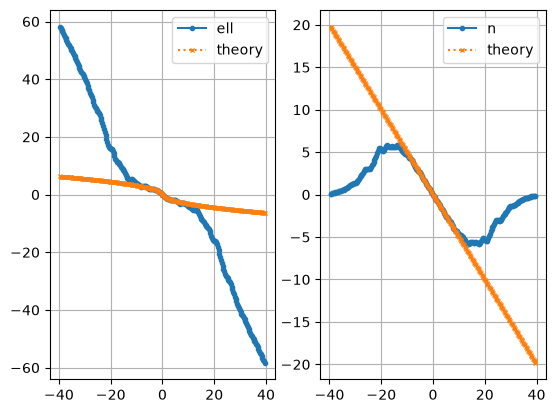

In [51]:
# lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: k**3/6 - k, n_t = lambda k: -0.5*k)
lsm.plot_symbol_fit(k = kdv1.k, idx_range = (idx_n, idx_p), ell_t = lambda k: -np.sign(k)*np.sqrt(k*np.tanh(k)), n_t = lambda k: -0.5*k)
